# 04 · Which LEMIS records should the model learn from?

**The question.** WildGuard's model learns from LEMIS and is applied to CITES, which covers CITES-listed species only. Most of LEMIS is not CITES-listed (notebook 03, X2). Should the model learn from every LEMIS line item, or only from the ones that look like CITES? This is the open decision on the training population in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md) §2.2.

**The method.** Train the same model on four candidate populations, changing nothing else, and test every candidate on **the same held-out records**: the ones most like CITES.

| Candidate | Learns from (training years 2000–2010) |
|---|---|
| **A** | every line item (the current pipeline) |
| **B** | animals with a class: drops rows without a class (mostly placeholder genera) and plants, fungi and bacteria |
| **C** | species with a CITES listing in force in the shipment year (species-level name match) |
| **C+** | C, plus line items whose genus had a CITES-listed species in force that year |

**Decision rule, fixed before any result was seen:**

1. **Evaluation set *E*:** LEMIS line items from the evaluation years (2013–2014 in the first run, 2011 in the rerun; see below) whose species had a CITES listing in force in the shipment year. *E-commercial* is its commercial-purpose part.
2. **Primary metric:** recall at a 1% review budget, the share of *E*'s enforcement cases found in the top 1% of *E*'s records, ranked by each candidate's score.
3. **The rule:**
   - **C or C+ replaces B** only if its recall at 1% beats B's, with the 95% paired-bootstrap interval of the difference above zero, on *E* **and** on *E-commercial*. If both qualify, take the one with the higher recall on *E*.
   - **B replaces A** unless A beats B in the same way.

   The bootstrap resamples **shipments**, not line items, because line items of one shipment are not independent (notebook 01, L1 and L5).
4. **Reported but not deciding:**
   - average precision and recall at 5% on *E*;
   - recall at 1% per shipment;
   - every metric on all evaluation-year records;
   - two CITES-side checks: how close each training population is to CITES, and how much the CITES top 1% changes between candidates.

**What is held fixed across candidates:**
- the year split (first run: train 2000–2010, validate 2011–2012, evaluate 2013–2014; rerun: train 2000–2010, validate 2012, evaluate 2011);
- the feature set (`SHARED_FEATURES`, the fields both datasets record), with peer norms and category vocabularies learned once from all training-year line items;
- one XGBoost configuration (first run: the pipeline's settings at the time, with class weights; rerun: the settings chosen in notebook 10);
- early stopping on the same validation set, the validation-year line items with a species-level listing;
- three random seeds per candidate.

The comparison covers the **supervised model only**. The unsupervised detectors use no labels, so the training population does not reach them in the same way.

**The appendix feature** is the listing **in force in the shipment year**, ignoring Appendix N: the most recent appendix CITES recorded for the species (else its genus, when no species is named) in or before that year (notebook 03, X8; notebook 06, G6). The first run derived it here; the rerun reads it from the rebuilt aligned files, where the pipeline now uses the same rule.

**Rerun on the rebuilt data (31 October 2026).** Population B was chosen on the first run. The rerun checks that choice on the rebuilt data (`SYSTEM CODE/DESIGN_QUESTIONS.md`, Part C), with the rule unchanged and three changes, all fixed before the rerun's results were seen:
1. **Evaluated on 2011, not 2013–2014.** The design now reserves 2013–2014 for the one test of the finished system (B1), which has already run; the design experiments were judged on 2011. Early stopping moves to 2012, so it never sees the evaluation year. 2011 has about half the listed cases of 2013–2014, so the intervals are wider, and the numbers are not like-for-like with the first run's.
2. **The XGBoost settings chosen in notebook 10** (no class weights, depth 6, learning rate 0.05, minimum child weight 20) replace the earlier pipeline's (depth 8, learning rate 0.08, class weights), so the check speaks for the deployed model. Every candidate still uses the same settings.
3. **The rule is also applied with PR-AUC.** Design question B4 made PR-AUC the deciding metric of the design, because recall at 1% is capped near 0.42 here (cases are 2.4% of listed line items, so a 1% budget has fewer slots than there are cases). The rule as written (recall at 1%) is applied first; the same rule with PR-AUC is reported beside it.

The inputs change with the rebuilt data: the aligned files of the rebuilt data step (codes, product groups, the listing in force), the 21 shared features (B8), and CITES records described with LEMIS peer norms (S2.1).


In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import roc_auc_score

import eda_setup as E
import experiment_setup as X_
from wildguard.evaluate import evaluate_scores

E.style()
con = E.connect()


def Q(sql):
    return E.q(con, sql)


# NB04_SAMPLE < 1 runs a quick smoke test on a sample of shipments
SAMPLE = float(os.environ.get("NB04_SAMPLE", "1"))
SEEDS = (0, 1, 2) if SAMPLE == 1 else (0,)
N_BOOT = 1000 if SAMPLE == 1 else 50
BUDGET = 0.01
CANDIDATES = ["A", "B", "C", "C+"]
COLOURS = {"A": "#9b9a96", "B": E.LEMIS_C, "C": E.CITES_C, "C+": E.THIRD_C}
# which CITES records the CITES-side checks (section 6) score: Decision 1, notebook 05 (rule D)
CITES_RULE = "D"

## 1. Listing status in the shipment year

For each LEMIS species and shipment year, take the most recent appendix CITES recorded for that species **in or before** that year (Appendix N ignored; the strictest appendix when a year has several). The same is done for the genus, as a fallback. CITES records come from all years 1975–2026, so a listing is found as long as the species was ever traded under it before the shipment. The lookup, the year split, the features and the training procedure are shared with notebook 05 in [`experiment_setup.py`](experiment_setup.py).

In [2]:
df = X_.load_lemis(con, SAMPLE)
print(f"LEMIS line items: {len(df):,}")
level = np.select([df.sp_listed, df.gen_listed, df.animal],
                  ["species listed", "genus listed only", "animal, not matched"], "no class or not an animal")
df.assign(level=level).groupby("level").agg(
    line_items=("label", "size"), cases=("label", "sum"), case_rate=("label", "mean")
).sort_values("line_items", ascending=False).pipe(E.share, "line_items", "share")

LEMIS line items: 5,512,706


,line_items,cases,case_rate,share
level,,,,
"animal, not matched",2513670,20734,0.008248,45.6%
species listed,1385752,31743,0.02291,25.14%
genus listed only,1207698,37411,0.03098,21.91%
no class or not an animal,405586,5777,0.01424,7.36%


## 2. The candidate populations and the evaluation set

In [3]:
tr, _, _ = X_.split(df)
yr = df["year"].to_numpy()
va, ev = yr == X_.config.HELD_BACK_YEAR, yr == X_.config.SELECTION_YEAR   # rerun: 2012, 2011
animal, sp, gen = (df[c].to_numpy() for c in ("animal", "sp_listed", "gen_listed"))
commercial = (df["purpose"] == "T").to_numpy()

POP = {"A": tr, "B": tr & animal, "C": tr & sp, "C+": tr & gen}
VAL = va & sp                         # early stopping, the same for every candidate
EVAL = {"E": ev & sp, "E-commercial": ev & sp & commercial, "all of 2011": ev}

y = df["label"].to_numpy()
rows = {f"train {k}": m for k, m in POP.items()} | {"validation (listed)": VAL} | EVAL
pd.DataFrame({"line_items": [m.sum() for m in rows.values()],
              "cases": [y[m].sum() for m in rows.values()],
              "case_rate": [y[m].mean() for m in rows.values()],
              "shipments": [df.loc[m, "shipment_id"].nunique() for m in rows.values()]},
             index=list(rows))

,line_items,cases,case_rate,shipments
train A,3877130,67149,0.01732,1493154
train B,3562032,63297,0.01777,1382934
train C,934559,22179,0.02373,397327
train C+,1837606,49032,0.02668,709169
validation (listed),114687,2403,0.02095,45222
E,101932,2417,0.02371,41076
E-commercial,77754,1075,0.01383,23296
all of 2011,396038,7926,0.02001,149295


Every candidate has tens of thousands of enforcement cases to learn from, so even the smallest population (C) is not short of data for a tree model. The case rate is higher among listed species, which is why each candidate must be tested on the same records: average precision rises with the base rate, so testing each model on its own population would favour whichever population has the easier mix.

In [4]:
t0 = time.time()
X, CATS = X_.build_features(df, tr)    # peer norms and category sets: all training years
ship = df["shipment_id"].to_numpy()
print(f"features for {len(X):,} line items ({time.time() - t0:.0f}s)")

features for 5,512,706 line items (29s)


## 3. Training

The XGBoost settings chosen in notebook 10 (no class weights, depth 6, learning rate 0.05, minimum child weight 20), with early stopping on average precision over the 2012 listed line items and the seed varied (`experiment_setup.fit_chosen`).

In [5]:
models, log = {}, []
for c in CANDIDATES:
    for seed in SEEDS:
        t = time.time()
        models[c, seed] = X_.fit_chosen(X, y, POP[c], VAL, seed)
        log.append({"candidate": c, "seed": seed, "train_rows": int(POP[c].sum()),
                    "best_iteration": models[c, seed].best_iteration,
                    "seconds": round(time.time() - t)})
        print(log[-1])
pd.DataFrame(log)

{'candidate': 'A', 'seed': 0, 'train_rows': 3877130, 'best_iteration': 706, 'seconds': 90}


{'candidate': 'A', 'seed': 1, 'train_rows': 3877130, 'best_iteration': 657, 'seconds': 86}


{'candidate': 'A', 'seed': 2, 'train_rows': 3877130, 'best_iteration': 879, 'seconds': 113}


{'candidate': 'B', 'seed': 0, 'train_rows': 3562032, 'best_iteration': 706, 'seconds': 61}


{'candidate': 'B', 'seed': 1, 'train_rows': 3562032, 'best_iteration': 638, 'seconds': 56}


...

{'candidate': 'C', 'seed': 2, 'train_rows': 934559, 'best_iteration': 432, 'seconds': 15}


{'candidate': 'C+', 'seed': 0, 'train_rows': 1837606, 'best_iteration': 948, 'seconds': 45}


{'candidate': 'C+', 'seed': 1, 'train_rows': 1837606, 'best_iteration': 822, 'seconds': 41}


{'candidate': 'C+', 'seed': 2, 'train_rows': 1837606, 'best_iteration': 647, 'seconds': 33}


,candidate,seed,train_rows,best_iteration,seconds
0,A,0,3877130,706,90
1,A,1,3877130,657,86
2,A,2,3877130,879,113
3,B,0,3562032,706,61
4,B,1,3562032,638,56
5,B,2,3562032,699,60
6,C,0,934559,365,14
7,C,1,934559,471,16
8,C,2,934559,432,15
9,C+,0,1837606,948,45


In [6]:
# each candidate's score: the mean of its three seeds' probabilities, on every 2011 row
S_ev = {c: np.mean([models[c, s].predict_proba(X[ev])[:, 1] for s in SEEDS], axis=0)
        for c in CANDIDATES}
S_seed = {(c, s): models[c, s].predict_proba(X[ev])[:, 1] for c in CANDIDATES for s in SEEDS}
y_ev, ship_ev = y[ev], ship[ev]
sub = {k: m[ev] for k, m in EVAL.items()}      # evaluation sets as masks within 2011

## 4. Results on the evaluation set

In [7]:
def metrics(yy, ss):
    m = evaluate_scores(yy, ss, 0.5)
    return {"recall@1%": m["recall@1%"], "recall@5%": m["recall@5%"],
            "precision@1%": m["precision@1%"], "avg_precision": m["pr_auc"]}


def shipment_recall(c, mask):
    g = pd.DataFrame({"s": ship_ev[mask], "y": y_ev[mask], "p": S_ev[c][mask]}).groupby("s").max()
    return metrics(g["y"].to_numpy(), g["p"].to_numpy())["recall@1%"]


res = {}
for c in CANDIDATES:
    for k, m in sub.items():
        for name, v in metrics(y_ev[m], S_ev[c][m]).items():
            res[(k, name), c] = v
    res[("E", "shipment recall@1%"), c] = shipment_recall(c, sub["E"])
table = pd.Series(res).unstack()[CANDIDATES]
table.index = pd.MultiIndex.from_tuples(table.index, names=["evaluated on", "metric"])
table.sort_index().style.format("{:.4f}").highlight_max(axis=1, props="font-weight: bold")

**Seed spread.** Recall at 1% on *E* for each seed separately. If seeds of one candidate differ by as much as the candidates do, no single run should be trusted:

In [8]:
spread = pd.DataFrame({c: [metrics(y_ev[sub["E"]], S_seed[c, s][sub["E"]])["recall@1%"]
                           for s in SEEDS] for c in CANDIDATES}, index=[f"seed {s}" for s in SEEDS])
spread.loc["range"] = spread.max() - spread.min()
spread.style.format("{:.4f}")

,A,B,C,C+
seed 0,0.3868,0.3885,0.3761,0.3827
seed 1,0.3852,0.3823,0.3835,0.3926
seed 2,0.3856,0.3794,0.3868,0.3786
range,0.0017,0.0091,0.0108,0.0141


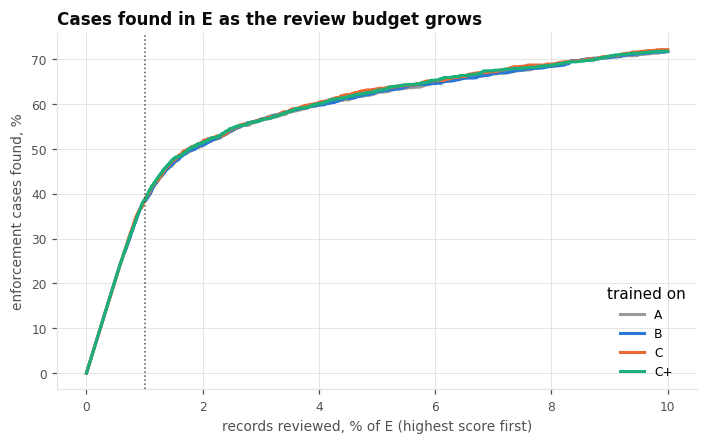

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
m = sub["E"]
for c in CANDIDATES:
    s = S_ev[c][m]
    o = np.argsort(-s, kind="stable")
    caught = np.cumsum(y_ev[m][o]) / y_ev[m].sum()
    frac = np.arange(1, len(o) + 1) / len(o)
    k = frac <= 0.10
    ax.plot(frac[k] * 100, caught[k] * 100, color=COLOURS[c], lw=2, label=c)
ax.axvline(BUDGET * 100, color=E.INK_2, lw=1, ls=":")
ax.set_xlabel("records reviewed, % of E (highest score first)")
ax.set_ylabel("enforcement cases found, %")
ax.set_title("Cases found in E as the review budget grows", loc="left")
ax.legend(title="trained on", frameon=False)
plt.show()

## 5. Applying the decision rule

Paired bootstrap: each of 1,000 resamples draws *E*'s shipments with replacement, and every candidate is scored on the same resample. The table gives each candidate's recall at 1% minus the comparison candidate's, with its 95% interval.

In [10]:
def weighted_recall_at(order, yy, w, budget=BUDGET):
    ws = w[order]
    top = np.cumsum(ws) <= budget * ws.sum()
    return (ws[top] * yy[order][top]).sum() / (w * yy).sum()


def bootstrap(mask, seed=37):
    codes, uniq = pd.factorize(ship_ev[mask])
    yy = y_ev[mask]
    orders = {c: np.argsort(-S_ev[c][mask], kind="stable") for c in CANDIDATES}
    rng = np.random.default_rng(seed)
    out = {c: np.empty(N_BOOT) for c in CANDIDATES}
    for b in range(N_BOOT):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes].astype(float)
        for c in CANDIDATES:
            out[c][b] = weighted_recall_at(orders[c], yy, w)
    return out


boot = {k: bootstrap(sub[k]) for k in ("E", "E-commercial")}
rows = []
for k, bs in boot.items():
    for c, ref in (("C", "B"), ("C+", "B"), ("A", "B"), ("C", "C+")):
        d = bs[c] - bs[ref]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"evaluated on": k, "comparison": f"{c} − {ref}", "difference": d.mean(),
                     "95% low": lo, "95% high": hi,
                     "verdict": "higher" if lo > 0 else "lower" if hi < 0 else "no clear difference"})
ci = pd.DataFrame(rows)
ci.style.format({"difference": "{:+.4f}", "95% low": "{:+.4f}", "95% high": "{:+.4f}"})

,evaluated on,comparison,difference,95% low,95% high,verdict
0,E,C − B,+0.0009,-0.0074,+0.0099,no clear difference
1,E,C+ − B,+0.0030,-0.0024,+0.0102,no clear difference
2,E,A − B,+0.0028,-0.0025,+0.0086,no clear difference
3,E,C − C+,-0.0021,-0.0083,+0.0039,no clear difference
4,E-commercial,C − B,+0.0129,-0.0028,+0.0277,no clear difference
5,E-commercial,C+ − B,+0.0072,-0.0037,+0.0177,no clear difference
6,E-commercial,A − B,-0.0006,-0.0098,+0.0079,no clear difference
7,E-commercial,C − C+,+0.0058,-0.0076,+0.0190,no clear difference


In [11]:
def beats(c, ref):
    return all(((ci["evaluated on"] == k) & (ci["comparison"] == f"{c} − {ref}")
                & (ci["95% low"] > 0)).any() for k in ("E", "E-commercial"))


base = "A" if beats("A", "B") else "B"
qualify = [c for c in ("C", "C+") if base == "B" and beats(c, "B")]
winner = max(qualify, key=lambda c: table.loc[("E", "recall@1%"), c]) if qualify else base
print(f"A clearly better than B on both sets: {beats('A', 'B')}")
for c in ("C", "C+"):
    print(f"{c} clearly better than B on both sets: {beats(c, 'B')}")
print(f"\nDecision under the pre-stated rule: train on population {winner}")

A clearly better than B on both sets: False
C clearly better than B on both sets: False
C+ clearly better than B on both sets: False

Decision under the pre-stated rule: train on population B


**The same rule with PR-AUC (B4).** The paired bootstrap of the same shipments, with PR-AUC (average precision) in place of recall at 1%: B is replaced only by a candidate whose interval lies above zero on both *E* and *E-commercial*.

In [12]:
PAIRS = [("C", "B"), ("C+", "B"), ("A", "B"), ("C", "C+")]
ci_pr = pd.concat([X_.pr_auc_bootstrap(y_ev[sub[k]], {c: S_ev[c][sub[k]] for c in CANDIDATES},
                                       ship_ev[sub[k]], PAIRS, n_boot=N_BOOT).assign(**{"evaluated on": k})
                   for k in ("E", "E-commercial")], ignore_index=True)
ci_pr["comparison"] = ci_pr["a"] + " − " + ci_pr["b"]
ci_pr["verdict"] = np.where(ci_pr["low_95"] > 0, "higher",
                            np.where(ci_pr["high_95"] < 0, "lower", "no clear difference"))


def beats_pr(c, ref):
    return all(((ci_pr["evaluated on"] == k) & (ci_pr["comparison"] == f"{c} − {ref}")
                & (ci_pr["low_95"] > 0)).any() for k in ("E", "E-commercial"))


base_pr = "A" if beats_pr("A", "B") else "B"
qualify_pr = [c for c in ("C", "C+") if base_pr == "B" and beats_pr(c, "B")]
winner_pr = max(qualify_pr, key=lambda c: table.loc[("E", "avg_precision"), c]) if qualify_pr else base_pr
print(f"Decision under the same rule with PR-AUC: train on population {winner_pr}")
ci_pr[["evaluated on", "comparison", "pr_auc_a", "pr_auc_b", "difference", "low_95", "high_95",
       "verdict"]].style.format({"pr_auc_a": "{:.4f}", "pr_auc_b": "{:.4f}", "difference": "{:+.4f}",
                                 "low_95": "{:+.4f}", "high_95": "{:+.4f}"})

Decision under the same rule with PR-AUC: train on population C


,evaluated on,comparison,pr_auc_a,pr_auc_b,difference,low_95,high_95,verdict
0,E,C − B,0.5755,0.5689,+0.0066,+0.0015,+0.0116,higher
1,E,C+ − B,0.5743,0.5689,+0.0054,+0.0024,+0.0088,higher
2,E,A − B,0.5689,0.5689,+0.0001,-0.0012,+0.0013,no clear difference
3,E,C − C+,0.5755,0.5743,+0.0012,-0.0036,+0.0057,no clear difference
4,E-commercial,C − B,0.3297,0.3129,+0.0166,+0.0056,+0.0275,higher
5,E-commercial,C+ − B,0.3198,0.3129,+0.0068,+0.0019,+0.0120,higher
6,E-commercial,A − B,0.3122,0.3129,-0.0007,-0.0032,+0.0017,no clear difference
7,E-commercial,C − C+,0.3297,0.3198,+0.0097,-0.0006,+0.0190,no clear difference


## 6. Checks on CITES itself

CITES has no labels, so these checks cannot pick a winner. They show whether the choice matters where the model is deployed.

**Does the CITES top 1% change?** Each candidate's top 1% of CITES records in each year, and the share of it that another candidate's top 1% also contains. Both lists have the same length, so the table is symmetric. 100% would mean the choice of training population makes no difference to what a reviewer sees.

**CITES records used:** 2015–2024, chosen by the mirror-record rule of Decision 1 (notebook 05, rule D): exporter-reported records plus importer-reported records with no exact exporter counterpart. Appendix N, source `I` and purpose `L` removed ([`ALIGNING`](../../DATA/ALIGNING_LEMIS_AND_CITES.md) §1.2). Both datasets use the CITES codes (ALIGNING §2.1), so no recoding is needed. The features are the pipeline's CITES features, described with LEMIS peer norms (S2.1, notebook 08): those of the deployed model (2000–2014), while the candidates were trained with norms from 2000–2010.

In [13]:
cites, Xc = X_.load_cites(CATS, keep=X_.queue_rids(con, CITES_RULE))
cy = cites["year"].to_numpy()
SC = {c: np.mean([models[c, s].predict_proba(Xc)[:, 1] for s in SEEDS], axis=0) for c in CANDIDATES}
print(f"CITES records scored: {len(Xc):,} (mirror-record rule {CITES_RULE})")
TOP = {c: X_.top_within_year(SC[c], cy, BUDGET) for c in CANDIDATES}
# both lists have the same length, so the share is the same read either way
overlap = pd.DataFrame({c: {r: (TOP[c] & TOP[r]).sum() / TOP[c].sum() for r in CANDIDATES}
                        for c in CANDIDATES})
overlap.style.format("{:.1%}")

CITES records scored: 5,465,862 (mirror-record rule D)


,A,B,C,C+
A,100.0%,93.6%,78.5%,82.1%
B,93.6%,100.0%,78.7%,82.4%
C,78.5%,78.7%,100.0%,82.3%
C+,82.1%,82.4%,82.3%,100.0%


**How close is each training population to CITES?** A classifier is trained to tell a population's records from CITES records, using only raw, directly comparable fields, the same fields as `wildguard.domain_shift`. An AUC of 0.5 means the classifier cannot tell them apart; 1.0 means it always can.

In [14]:
RAW_COMPARABLE = ["class", "product_group", "unit_group", "purpose", "source", "appendix",
                  "origin_region", "exporter_region", "genus_top", "exporter_top", "origin_top",
                  "log_qty", "reexport_flag", "is_wild"]


def domain_auc(Xa, Xb, n=250_000, seed=37):
    rng = np.random.default_rng(seed)
    ia = rng.choice(len(Xa), min(len(Xa), n), replace=False)
    ib = rng.choice(len(Xb), min(len(Xb), n), replace=False)
    Z = pd.concat([Xa.iloc[ia], Xb.iloc[ib]], ignore_index=True)
    d = np.r_[np.zeros(len(ia)), np.ones(len(ib))]
    p = rng.permutation(len(Z))
    cut = int(0.7 * len(Z))
    clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist",
                            enable_categorical=True, subsample=0.8, colsample_bytree=0.8,
                            n_jobs=8, random_state=seed)
    clf.fit(Z.iloc[p[:cut]], d[p[:cut]])
    return roc_auc_score(d[p[cut:]], clf.predict_proba(Z.iloc[p[cut:]])[:, 1])


Xc_raw = Xc[RAW_COMPARABLE]
pd.Series({c: domain_auc(X.loc[POP[c], RAW_COMPARABLE], Xc_raw) for c in CANDIDATES},
          name="AUC: training population vs CITES").to_frame().style.format("{:.3f}")

,AUC: training population vs CITES
A,0.986
B,0.985
C,0.956
C+,0.972


## What this means for Decision 2

These findings are from the rerun on the rebuilt data, evaluated on 2011 (see the note at the top). The first run's findings, on 2013–2014 with the earlier settings, are in the git history.

| # | Finding | What it means for Decision 2 |
|---|---|---|
| P1 | **Recall at 1% cannot separate the candidates on CITES-listed 2011 records (*E*).** It is 0.383–0.386 for all four. Every paired difference has a 95% interval that includes zero, on *E* and on *E-commercial*, and the spread between seeds of one candidate (up to 0.014) is larger than the gaps between candidates | Under the rule as written, B stays: no candidate beats it on both sets |
| P2 | **PR-AUC separates them, slightly in favour of training on listed species.** On *E*: C 0.576, C+ 0.574, B 0.569, A 0.569; C − B +0.0066 (95% interval +0.0015 to +0.0116). On *E-commercial*: C 0.330 against B 0.313, +0.0166 (+0.0056 to +0.0275). C+ also beats B on both sets; C and C+ do not differ | With PR-AUC, the design's deciding metric (DESIGN_QUESTIONS B4), the same rule picks C. The gain is small and largest on commercial listed trade, where the first run also found C better |
| P3 | **On all 2011 records, C is much worse** (PR-AUC 0.307, against B 0.544 and A 0.672) | Expected and irrelevant to deployment: C never sees unlisted taxa. A also trains on the rows CITES never contains (plants, fungi, rows without a class), which are part of this set |
| P4 | **The choice changes part of what a CITES reviewer sees.** On rule D's records, the top 1% per year under B and C share 78.7%; A and B share 93.6% (first run: 66.1% and 77.0%) | About a fifth of the records reviewed first depend on this decision |
| P5 | **No training population is close to CITES.** Domain-classifier AUC against rule D's records: A 0.986, B 0.985, C+ 0.972, C 0.956 | Restricting to listed species narrows the shift only slightly, so the population choice does not fix it |

**Under the rule as written, the decision is B** (animals with a class): A does no better than B, and neither C nor C+ beats B on both *E* and *E-commercial* at a 1% budget. **With PR-AUC, the same rule picks C** (CITES-listed species only).

**Kept: B (decided 31 October 2026).** This rerun came after the one test of the finished system on 2013–2014, which used B. Switching now would either deploy a model that was never tested or use the test years a second time, and the protocol (DESIGN_QUESTIONS B10) rules out both. The deployed system therefore keeps B, and the report states that this check, judged on PR-AUC, favours training on listed species by a small margin. Training on listed species only is future work, to be tested on a held-out period that has not been used.

**Limits of this experiment:**
- *E* is US import declarations of CITES-listed species, a stand-in for CITES, not CITES itself.
- Listing status comes from name matching against CITES records, so synonyms are missed (X2).
- 2011 has about half the listed cases of 2013–2014 (2,417 against 4,744), so the intervals are wider than in the first run.
- Only XGBoost was compared, not the deployed two-model ensemble.